# Atividade
## Normalização, escalonamento e codificação de dados categóricos
Ciência de Dados · Bacharelado em Engenharia de Software · UNIFSA


### Contexto
Uma operadora de telecomunicações deseja compreender melhor sua base de clientes. A diretoria comercial solicitou à equipe de dados dois produtos:

1. um **índice de valor do cliente**, que permita ranquear os clientes combinando tempo de relacionamento e faturamento;
2. uma **análise do cancelamento (churn)**, que indique quais características dos clientes estão associadas a uma maior taxa de cancelamento.

As métricas disponíveis estão em escalas diferentes e grande parte das informações está em formato textual. Antes de qualquer análise, é necessário preparar os dados.

### Base de dados
IBM. *Telco Customer Churn* (base de exemplo). 7.043 clientes e 21 colunas. Endereço público para carga:

https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv


### Dicionário de dados (colunas utilizadas)
| Coluna | Descrição |
|---|---|
| customerID | identificador do cliente |
| gender | sexo do titular (Male, Female) |
| Partner, Dependents | possui cônjuge; possui dependentes (Yes, No) |
| tenure | tempo de relacionamento, em meses |
| PhoneService, PaperlessBilling | possui telefone; usa fatura digital (Yes, No) |
| MultipleLines | possui múltiplas linhas (Yes, No, No phone service) |
| InternetService | tipo de internet (DSL, Fiber optic, No) |
| OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies | serviços adicionais (Yes, No, No internet service) |
| Contract | tipo de contrato (Month-to-month, One year, Two year) |
| PaymentMethod | forma de pagamento (quatro categorias) |
| MonthlyCharges | valor da mensalidade |
| TotalCharges | valor total faturado desde o início do contrato |
| Churn | o cliente cancelou o serviço no último mês (Yes, No) |

## Parte 1 — Carga e preparação dos dados

**1.1** Carregue a base a partir do endereço público informado no início do notebook. Exiba o número de linhas e de colunas e os tipos de cada coluna.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(URL)

print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}\n")
print(df.dtypes)

Linhas: 7043 | Colunas: 21

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


**1.2** A coluna `TotalCharges` deveria ser numérica, mas foi lida como texto. Converta-a para numérico e identifique os registros que não puderam ser convertidos. Examine o valor de `tenure` nesses registros.

In [20]:
df["TotalCharges_num"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

invalidos = df[df["TotalCharges_num"].isna()]
print(f"Registros não convertidos: {len(invalidos)}\n")
print("Valor original de TotalCharges nesses registros:", invalidos["TotalCharges"].unique())
print("\nValores de tenure nesses registros:")
print(invalidos["tenure"].value_counts())
invalidos[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Registros não convertidos: 11

Valor original de TotalCharges nesses registros: [' ']

Valores de tenure nesses registros:
tenure
0    11
Name: count, dtype: int64


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.5500,,No
753,3115-CZMZD,0,20.2500,,No
936,5709-LVOEQ,0,80.8500,,No
1082,4367-NUYAO,0,25.7500,,No
1340,1371-DWPAZ,0,56.0500,,No
3331,7644-OMVMY,0,19.8500,,No
3826,3213-VVOLG,0,25.3500,,No
4380,2520-SGTTA,0,20.0000,,No
5218,2923-ARZLG,0,19.7000,,No
6670,4075-WKNIU,0,73.3500,,No


**1.3** Com base no que foi observado em 1.2, decida como tratar esses registros e implemente a decisão. Justifique a escolha considerando o significado do negócio (o que representa um cliente com esse valor de `tenure`?).

In [21]:
df["TotalCharges"] = df["TotalCharges_num"].fillna(0)
df = df.drop(columns="TotalCharges_num")

assert df["TotalCharges"].isna().sum() == 0
print("Nulos em TotalCharges:", df["TotalCharges"].isna().sum())
print("Registros com tenure == 0:", (df["tenure"] == 0).sum(), "| todos com TotalCharges == 0:",
      (df.loc[df["tenure"] == 0, "TotalCharges"] == 0).all())
print("Dimensão final:", df.shape)

Nulos em TotalCharges: 0
Registros com tenure == 0: 11 | todos com TotalCharges == 0: True
Dimensão final: (7043, 21)


**Resposta:** Os 11 registros não convertidos continham apenas um espaço em branco em `TotalCharges`, e todos têm `tenure = 0`. Um cliente com `tenure = 0` acabou de contratar o serviço e ainda não completou o primeiro mês, então nada foi faturado: o valor correto é **0**, e não "desconhecido". Por isso optei por **substituir por 0 e manter os registros**. Excluí-los descartaria clientes reais (e todos eles ainda não cancelaram), e imputar média ou mediana criaria um faturamento total que nunca existiu, distorcendo justamente o índice de valor da Parte 2.

## Parte 2 — Escalonamento e índice de valor do cliente

**2.1** Apresente as estatísticas descritivas de `tenure`, `MonthlyCharges` e `TotalCharges`. Compare as amplitudes (mínimo e máximo) das três métricas.

In [22]:
num = ["tenure", "MonthlyCharges", "TotalCharges"]
display(df[num].describe().T)

amp = pd.DataFrame({"mínimo": df[num].min(), "máximo": df[num].max(),
                    "amplitude": df[num].max() - df[num].min(),
                    "desvio-padrão": df[num].std()})
amp["amplitude / amplitude de tenure"] = amp["amplitude"] / amp.loc["tenure", "amplitude"]
display(amp)

,count,mean,std,min,25%,50%,75%,max
tenure,"7,043.0000",32.3711,24.5595,0.0000,9.0000,29.0000,55.0000,72.0000
MonthlyCharges,"7,043.0000",64.7617,30.0900,18.2500,35.5000,70.3500,89.8500,118.7500
TotalCharges,"7,043.0000","2,279.7343","2,266.7945",0.0000,398.5500,"1,394.5500","3,786.6000","8,684.8000"


,mínimo,máximo,amplitude,desvio-padrão,amplitude / amplitude de tenure
tenure,0.0000,72.0000,72.0000,24.5595,1.0000
MonthlyCharges,18.2500,118.7500,100.5000,30.0900,1.3958
TotalCharges,0.0000,"8,684.8000","8,684.8000","2,266.7945",120.6222


**Resposta:** As três métricas estão em escalas muito diferentes: `tenure` vai de 0 a 72 (meses), `MonthlyCharges` de 18,25 a 118,75 e `TotalCharges` de 0 a 8.684,80. A amplitude de `TotalCharges` é cerca de 120 vezes a de `tenure`, e seu desvio-padrão (≈ 2.267) é cerca de 92 vezes o de `tenure` (≈ 24,6). Somar essas métricas sem tratamento faria a de maior escala dominar o resultado.

**2.2** Construa um **índice bruto** somando diretamente as três métricas.

*   Item da lista
*   Item da lista

Calcule a correlação do índice bruto com cada uma delas. Qual métrica determina o índice? Por quê?

In [23]:
indice_bruto = df[num].sum(axis=1)

print("Correlação do índice bruto com cada métrica:")
print(df[num].corrwith(indice_bruto))

Correlação do índice bruto com cada métrica:
tenure           0.8258
MonthlyCharges   0.6556
TotalCharges     1.0000
dtype: float64


**Resposta:** O índice bruto é determinado por `TotalCharges` (correlação ≈ 1,00; exatamente 0,99997), enquanto `tenure` (≈ 0,83) e `MonthlyCharges` (≈ 0,66) têm influência bem menor. A causa é a escala: numa soma direta, a variável de maior variância carrega quase toda a variação do resultado. `TotalCharges` tem desvio-padrão ≈ 2.267, contra ≈ 24,6 de `tenure` e ≈ 30,1 de `MonthlyCharges`. Na prática, o "índice" apenas repete o faturamento total.

**2.3** Padronize as três métricas com **z-score** e construa o **índice padronizado** como a soma das três métricas padronizadas. Repita o cálculo de correlações do item 2.2.

In [24]:
z = (df[num] - df[num].mean()) / df[num].std()
indice_z = z.sum(axis=1)

print("Correlação do índice padronizado com cada métrica:")
print(df[num].corrwith(indice_z))

Correlação do índice padronizado com cada métrica:
tenure           0.8166
MonthlyCharges   0.7477
TotalCharges     0.9754
dtype: float64


**Resposta:** Com o z-score, as três métricas passam a ter média 0 e desvio-padrão 1, e o domínio de `TotalCharges` cai de 0,99997 para ≈ 0,975. `tenure` (≈ 0,82) e `MonthlyCharges` (≈ 0,75) ficam muito mais próximas. Ainda assim, `TotalCharges` continua com a maior correlação, porque ela é correlacionada com as outras duas (ver 2.6) e está contada, em parte, duas vezes no índice.

2.4 Liste os 10 clientes com maior índice bruto e os 10 com maior índice padronizado. Quantos clientes aparecem nas duas listas? O que mudou no perfil dos clientes mais bem posicionados?

In [25]:
top_bruto = indice_bruto.nlargest(10).index
top_z = indice_z.nlargest(10).index

print("Top 10 - índice bruto:")
display(df.loc[top_bruto, ["customerID"] + num].assign(indice=indice_bruto[top_bruto]))
print("Top 10 - índice padronizado:")
display(df.loc[top_z, ["customerID"] + num].assign(indice=indice_z[top_z]))

comum = set(top_bruto) & set(top_z)
print(f"Clientes presentes nas duas listas: {len(comum)}")

perfil = pd.DataFrame({"top10 bruto": df.loc[top_bruto, num].mean(),
                       "top10 padronizado": df.loc[top_z, num].mean(),
                       "base inteira": df[num].mean()})
display(perfil)

for k in (50, 100, 500):
    n = len(set(indice_bruto.nlargest(k).index) & set(indice_z.nlargest(k).index))
    print(f"Interseção no top {k}: {n}")

Top 10 - índice bruto:


,customerID,tenure,MonthlyCharges,TotalCharges,indice
4610,2889-FPWRM,72,117.8000,"8,684.8000","8,874.6000"
4586,7569-NMZYQ,72,118.7500,"8,672.4500","8,863.2000"
6768,9739-JLPQJ,72,117.5000,"8,670.1000","8,859.6000"
5347,9788-HNGUT,72,116.9500,"8,594.4000","8,783.3500"
2187,8879-XUAHX,71,116.2500,"8,564.7500","8,752.0000"
6118,9924-JPRMC,72,118.2000,"8,547.1500","8,737.3500"
5558,0675-NCDYU,72,116.4000,"8,543.2500","8,731.6500"
2368,6650-BWFRT,72,117.1500,"8,529.5000","8,718.6500"
2603,0164-APGRB,72,114.9000,"8,496.7000","8,683.6000"
2115,8984-HPEMB,71,118.6500,"8,477.6000","8,667.2500"


Top 10 - índice padronizado:


,customerID,tenure,MonthlyCharges,TotalCharges,indice
4586,7569-NMZYQ,72,118.7500,"8,672.4500",6.2280
4610,2889-FPWRM,72,117.8000,"8,684.8000",6.2018
6768,9739-JLPQJ,72,117.5000,"8,670.1000",6.1854
6118,9924-JPRMC,72,118.2000,"8,547.1500",6.1544
5347,9788-HNGUT,72,116.9500,"8,594.4000",6.1337
2368,6650-BWFRT,72,117.1500,"8,529.5000",6.1117
2115,8984-HPEMB,71,118.6500,"8,477.6000",6.0980
5558,0675-NCDYU,72,116.4000,"8,543.2500",6.0929
2025,1488-PBLJN,72,116.8500,"8,477.7000",6.0789
4155,6904-JLBGY,72,117.3500,"8,436.2500",6.0772


Clientes presentes nas duas listas: 8


,top10 bruto,top10 padronizado,base inteira
tenure,71.8000,71.9000,32.3711
MonthlyCharges,117.2550,117.5600,64.7617
TotalCharges,"8,578.0700","8,563.3200","2,279.7343"


Interseção no top 50: 45
Interseção no top 100: 93
Interseção no top 500: 489


**Resposta:** **8 dos 10 clientes** aparecem nas duas listas. O perfil mudou pouco: nos dois rankings predominam clientes com `tenure` ≈ 72 meses e mensalidade ≈ US$ 117, bem acima da média da base (32 meses e US$ 64,76). A mudança é sutil: o índice bruto escolhe quem tem o maior faturamento total, e o padronizado passa a dar o mesmo peso a tempo e mensalidade, trocando 2 clientes por outros ligeiramente melhores nessas duas métricas (média de `MonthlyCharges` do top 10 sobe de ≈ 117,26 para ≈ 117,56). O efeito é pequeno porque `TotalCharges` é, em boa parte, resultado de `tenure` × `MonthlyCharges`; a diferença entre os índices aparece mais fora do topo.

2.5 Aplique o min-max às três métricas e construa um terceiro índice. Compare a ordenação dos clientes no índice min-max com a do índice padronizado (sugestão: correlação entre os dois índices).

In [26]:
mm = (df[num] - df[num].min()) / (df[num].max() - df[num].min())
indice_mm = mm.sum(axis=1)

print("Correlação de Pearson   (min-max x z-score):", round(indice_mm.corr(indice_z), 4))
print("Correlação de Spearman  (min-max x z-score):", round(indice_mm.corr(indice_z, method="spearman"), 4))
print("\nCorrelação do índice min-max com cada métrica:")
print(df[num].corrwith(indice_mm))
print("\nInterseção no top 10:", len(set(indice_mm.nlargest(10).index) & set(indice_z.nlargest(10).index)))

Correlação de Pearson   (min-max x z-score): 0.9995
Correlação de Spearman  (min-max x z-score): 0.9994

Correlação do índice min-max com cada métrica:
tenure           0.8331
MonthlyCharges   0.7314
TotalCharges     0.9741
dtype: float64

Interseção no top 10: 10


**Resposta:** Os índices min-max e padronizado são praticamente equivalentes: correlação de Pearson ≈ 0,9995 e de Spearman ≈ 0,9994, ou seja, a ordenação dos clientes é quase idêntica. Os dois métodos colocam as variáveis em escalas comparáveis (z-score: média 0 e desvio 1; min-max: intervalo [0, 1]) e diferem só por uma transformação linear em cada variável, com pequenas diferenças de peso entre elas. A escolha entre eles afeta pouco um ranking como este; o min-max é mais sensível a valores extremos, já que usa mínimo e máximo.

2.6 Calcule a matriz de correlação entre tenure, MonthlyCharges e TotalCharges. Considerando que o faturamento total resulta, aproximadamente, do tempo de relacionamento multiplicado pela mensalidade, discuta se faz sentido manter as três métricas no índice. Proponha e implemente a versão final do índice de valor do cliente.

In [27]:
print("Matriz de correlação:")
display(df[num].corr())

# Versão final: tempo de relacionamento + mensalidade (padronizados), sem TotalCharges
indice_final = z["tenure"] + z["MonthlyCharges"]

print("Correlação do índice final com cada métrica:")
print(df[num].corrwith(indice_final))
print("\nCorrelação com o índice padronizado de 3 métricas:", round(indice_final.corr(indice_z), 4))

ranking = df[["customerID"] + num].assign(indice_valor=indice_final).sort_values("indice_valor", ascending=False)
display(ranking.head(10))

Matriz de correlação:


,tenure,MonthlyCharges,TotalCharges
tenure,1.0000,0.2479,0.8262
MonthlyCharges,0.2479,1.0000,0.6512
TotalCharges,0.8262,0.6512,1.0000


Correlação do índice final com cada métrica:
tenure           0.7899
MonthlyCharges   0.7899
TotalCharges     0.9351
dtype: float64

Correlação com o índice padronizado de 3 métricas: 0.9902


,customerID,tenure,MonthlyCharges,TotalCharges,indice_valor
4586,7569-NMZYQ,72,118.7500,"8,672.4500",3.4078
6118,9924-JPRMC,72,118.2000,"8,547.1500",3.3895
4610,2889-FPWRM,72,117.8000,"8,684.8000",3.3762
3205,3810-DVDQQ,72,117.6000,"8,308.9000",3.3696
6768,9739-JLPQJ,72,117.5000,"8,670.1000",3.3663
2115,8984-HPEMB,71,118.6500,"8,477.6000",3.3638
4155,6904-JLBGY,72,117.3500,"8,436.2500",3.3613
2368,6650-BWFRT,72,117.1500,"8,529.5000",3.3546
5347,9788-HNGUT,72,116.9500,"8,594.4000",3.3480
2025,1488-PBLJN,72,116.8500,"8,477.7000",3.3447


**Resposta:** A matriz mostra `TotalCharges` fortemente correlacionada com `tenure` (≈ 0,83) e com `MonthlyCharges` (≈ 0,65), o que é esperado, pois o faturamento total é, aproximadamente, tempo × mensalidade. Manter as três métricas faz o índice contar tempo e mensalidade duas vezes (diretamente e via `TotalCharges`), com peso excessivo no faturamento acumulado e redundância de informação. A versão final proposta usa apenas **`tenure` e `MonthlyCharges` padronizadas por z-score**: `indice_valor = z(tenure) + z(MonthlyCharges)`. As duas variáveis têm correlação baixa entre si (≈ 0,25), então cada uma traz informação própria, e o índice resulta equilibrado (correlação ≈ 0,79 com cada uma). `TotalCharges` ainda influencia o ranking de forma indireta, pois é consequência das duas (correlação ≈ 0,94 com o índice final), mas sem ser contada em duplicidade.

Parte 3 — Forma da distribuição

3.1 Construa os histogramas das três métricas e calcule a assimetria de cada uma (.skew()).

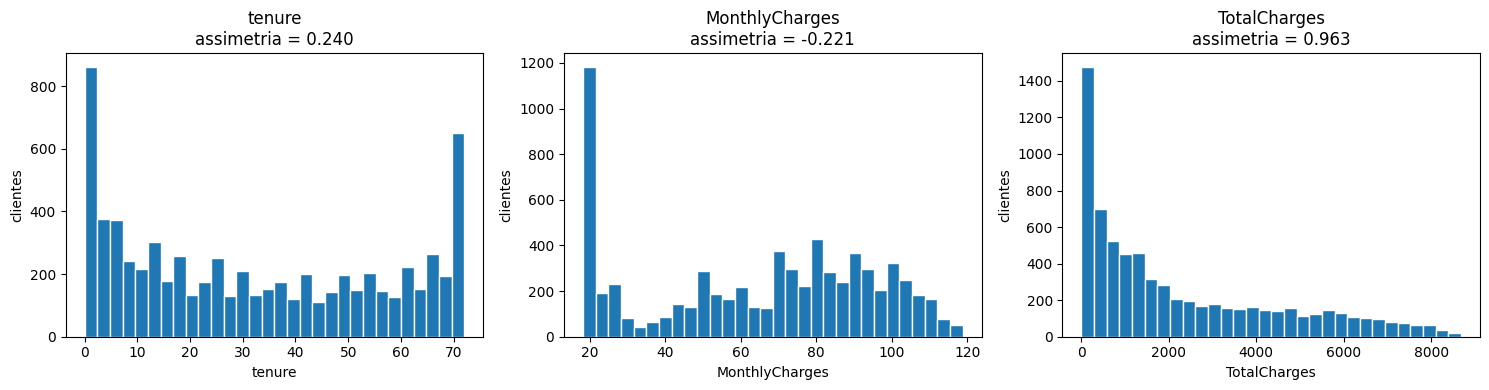

tenure            0.2395
MonthlyCharges   -0.2205
TotalCharges      0.9632
dtype: float64


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num):
    ax.hist(df[col], bins=30, edgecolor="white")
    ax.set_title(f"{col}\nassimetria = {df[col].skew():.3f}")
    ax.set_xlabel(col); ax.set_ylabel("clientes")
plt.tight_layout(); plt.show()

print(df[num].skew())

3.2 Aplique a transformação np.log1p à coluna TotalCharges. Compare o histograma e a assimetria antes e depois da transformação. A transformação logarítmica é adequada para esta coluna? Justifique com base nos valores obtidos.

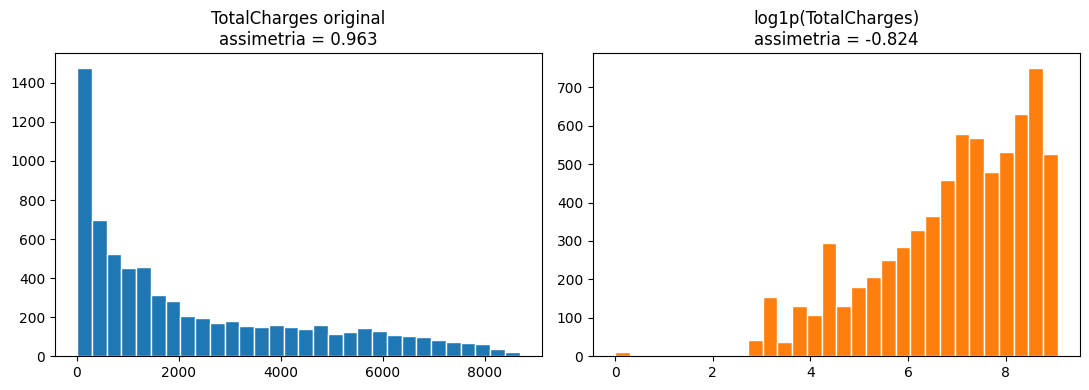

Assimetria antes : 0.963
Assimetria depois: -0.824


In [29]:
total_log = np.log1p(df["TotalCharges"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["TotalCharges"], bins=30, edgecolor="white")
axes[0].set_title(f"TotalCharges original\nassimetria = {df['TotalCharges'].skew():.3f}")
axes[1].hist(total_log, bins=30, edgecolor="white", color="tab:orange")
axes[1].set_title(f"log1p(TotalCharges)\nassimetria = {total_log.skew():.3f}")
plt.tight_layout(); plt.show()

print("Assimetria antes :", round(df["TotalCharges"].skew(), 3))
print("Assimetria depois:", round(total_log.skew(), 3))

**Resposta:** `TotalCharges` tem assimetria positiva forte (≈ +0,96, cauda longa à direita), enquanto `tenure` (≈ +0,24) e `MonthlyCharges` (≈ −0,22) são quase simétricas. Após `log1p`, a assimetria passa a ≈ −0,82: o valor absoluto caiu pouco (0,96 → 0,82) e o sinal **inverteu**, com cauda longa à esquerda. A causa são os 11 clientes com `TotalCharges = 0` e muitos clientes recentes, com valores baixos, que o logaritmo "estica". Portanto a transformação **não é adequada**: ela não deixa a distribuição simétrica, apenas troca o lado da assimetria. Não há ganho que justifique o uso e a variável fica mais difícil de interpretar.

## Parte 4 — Codificação das variáveis categóricas

**4.1** Classifique as variáveis abaixo e indique a técnica de codificação adequada, preenchendo a tabela.

| Variável | Tipo (nominal, ordinal ou binária) | Técnica de codificação |
|---|---|---|
| gender | | |
| Partner | | |
| PhoneService | | |
| MultipleLines | | |
| InternetService | | |
| OnlineSecurity | | |
| Contract | | |
| PaymentMethod | | |
| Churn | | |

| Variável | Tipo (nominal, ordinal ou binária) | Técnica de codificação |
|---|---|---|
| gender | binária (Male, Female) | mapeamento 0/1 |
| Partner | binária (Yes, No) | mapeamento 0/1 |
| PhoneService | binária (Yes, No) | mapeamento 0/1 |
| MultipleLines | nominal com 3 valores; "No phone service" equivale a "No" e a informação já está em `PhoneService`, então vira binária | mapeamento 0/1 (Yes = 1; demais = 0) |
| InternetService | nominal (DSL, Fiber optic, No), sem ordem natural | one-hot encoding |
| OnlineSecurity | nominal com 3 valores; "No internet service" equivale a "No" e a informação já está em `InternetService`, então vira binária | mapeamento 0/1 (Yes = 1; demais = 0) |
| Contract | ordinal (Month-to-month < One year < Two year) | codificação ordinal (0, 1, 2) |
| PaymentMethod | nominal (4 categorias), sem ordem natural | one-hot encoding |
| Churn | binária (variável-alvo) | mapeamento 0/1 (Yes = 1) |

4.2 Converta para 0 e 1 as variáveis binárias gender, Partner, Dependents, PhoneService, PaperlessBilling e Churn.

In [30]:
binarias = {"gender": {"Female": 0, "Male": 1}}
for col in ["Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]:
    binarias[col] = {"No": 0, "Yes": 1}

for col, mapa in binarias.items():
    df[col] = df[col].map(mapa)
    assert df[col].isna().sum() == 0, col

df[list(binarias)].head()

,gender,Partner,Dependents,PhoneService,PaperlessBilling,Churn
0,0,1,0,0,1,0
1,1,0,0,1,0,0
2,1,0,0,1,1,1
3,1,0,0,0,0,0
4,0,0,0,1,1,1


4.3 As colunas de serviços adicionais (OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies) e a coluna MultipleLines possuem três valores. Analise o significado de "No internet service" e "No phone service", decida como codificar essas colunas e implemente a decisão.

In [31]:
servicos = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
            "StreamingTV", "StreamingMovies", "MultipleLines"]

print("Valores antes da codificação:")
for col in servicos:
    print(f"{col:17s}", df[col].value_counts().to_dict())

# Yes = 1; "No" e "No internet/phone service" = 0
for col in servicos:
    df[col] = (df[col] == "Yes").astype(int)

print("\nValores depois:")
print(df[servicos].apply(lambda s: s.value_counts()).T)

Valores antes da codificação:
OnlineSecurity    {'No': 3498, 'Yes': 2019, 'No internet service': 1526}
OnlineBackup      {'No': 3088, 'Yes': 2429, 'No internet service': 1526}
DeviceProtection  {'No': 3095, 'Yes': 2422, 'No internet service': 1526}
TechSupport       {'No': 3473, 'Yes': 2044, 'No internet service': 1526}
StreamingTV       {'No': 2810, 'Yes': 2707, 'No internet service': 1526}
StreamingMovies   {'No': 2785, 'Yes': 2732, 'No internet service': 1526}
MultipleLines     {'No': 3390, 'Yes': 2971, 'No phone service': 682}

Valores depois:
                     0     1
OnlineSecurity    5024  2019
OnlineBackup      4614  2429
DeviceProtection  4621  2422
TechSupport       4999  2044
StreamingTV       4336  2707
StreamingMovies   4311  2732
MultipleLines     4072  2971


**Resposta:** "No internet service" (e "No phone service" em `MultipleLines`) indica que o cliente **não tem o serviço-base**, então não tem como contratar o adicional: do ponto de vista do cliente, é equivalente a "No" (não possui o serviço). Essa informação já está em `InternetService` (valor "No") e em `PhoneService`; manter uma terceira categoria nas colunas adicionais seria **redundante**. Por isso codifiquei essas colunas como **binárias (Yes = 1; "No" e "No ... service" = 0)**, o que evita criar sete colunas one-hot desnecessárias.

4.4 Codifique Contract de forma ordinal, respeitando a ordem de duração do contrato.

In [32]:
df["Contract"] = df["Contract"].map({"Month-to-month": 0, "One year": 1, "Two year": 2})
assert df["Contract"].isna().sum() == 0
df["Contract"].value_counts().sort_index()

,count
Contract,
0,3875
1,1473
2,1695


4.5 Aplique one-hot encoding a InternetService e PaymentMethod. Utilize ou não o parâmetro drop_first e justifique a escolha.

In [33]:
cat_original = df[["InternetService", "PaymentMethod"]].copy()

df = pd.get_dummies(df, columns=["InternetService", "PaymentMethod"], drop_first=True, dtype=int)

print("Colunas finais:", df.shape[1])
df.filter(regex="InternetService_|PaymentMethod_").head()

Colunas finais: 24


,InternetService_Fiber optic,InternetService_No,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,0,1,0
1,0,0,0,0,1
2,0,0,0,0,1
3,0,0,0,0,0
4,1,0,0,1,0


**Resposta:** Utilizei `drop_first=True`. Com k categorias, k colunas dummy são perfeitamente redundantes (a soma das colunas é sempre 1), o que gera multicolinearidade perfeita (a "armadilha da variável dummy"), problemática em regressões lineares e que duplica a informação. Com `drop_first=True` ficam k − 1 colunas, e a categoria omitida (`DSL` em `InternetService`; `Bank transfer (automatic)` em `PaymentMethod`) vira a **categoria de referência**, com valor 0 em todas as dummies. Nenhuma informação se perde, pois a categoria omitida é deduzida das demais.

Parte 5 — Análise do cancelamento para a diretoria comercial

5.1 Utilizando a coluna Churn codificada, calcule a taxa de cancelamento (proporção de clientes que cancelaram) por tipo de contrato, por forma de pagamento e por tipo de internet.

Taxa geral de cancelamento: 26.5%


--- Contract ---
Contract
Month-to-month    42.7 %
One year          11.3 %
Two year           2.8 %
Name: Churn, dtype: object

--- PaymentMethod ---
PaymentMethod
Electronic check             45.3 %
Mailed check                 19.1 %
Bank transfer (automatic)    16.7 %
Credit card (automatic)      15.2 %
Name: Churn, dtype: object

--- InternetService ---
InternetService
Fiber optic    41.9 %
DSL            19.0 %
No              7.4 %
Name: Churn, dtype: object


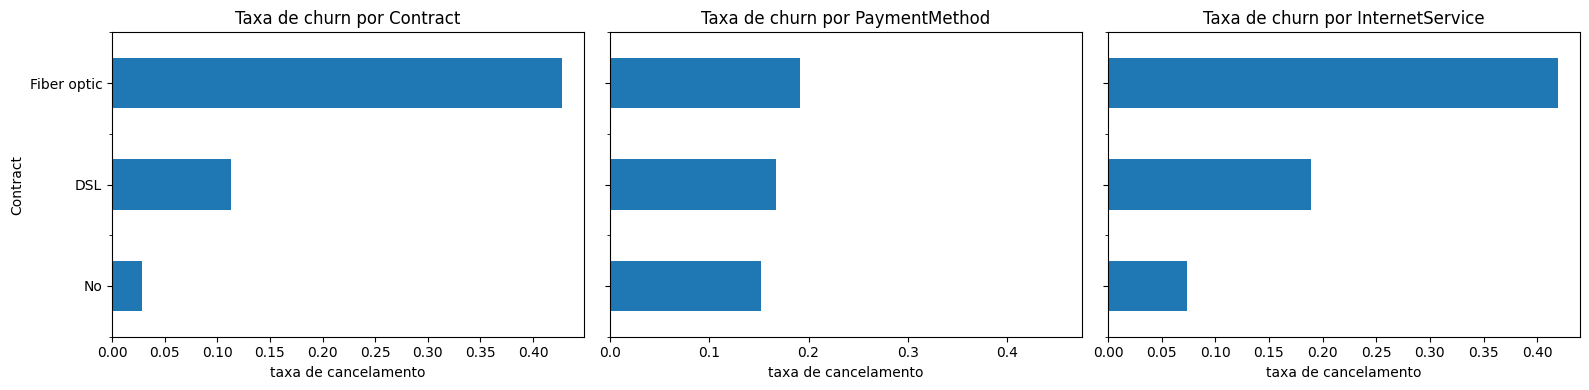

In [34]:
taxas = {}
contrato_nome = {0: "Month-to-month", 1: "One year", 2: "Two year"}

taxas["Contract"] = df.groupby("Contract")["Churn"].mean().rename(index=contrato_nome)
taxas["PaymentMethod"] = df["Churn"].groupby(cat_original["PaymentMethod"]).mean()
taxas["InternetService"] = df["Churn"].groupby(cat_original["InternetService"]).mean()

print(f"Taxa geral de cancelamento: {df['Churn'].mean():.1%}\n")
for nome, serie in taxas.items():
    print(f"\n--- {nome} ---")
    print((serie.sort_values(ascending=False) * 100).round(1).astype(str) + " %")

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (nome, serie) in zip(axes, taxas.items()):
    serie.sort_values().plot.barh(ax=ax)
    ax.set_title(f"Taxa de churn por {nome}"); ax.set_xlabel("taxa de cancelamento")
plt.tight_layout(); plt.show()

5.2 Calcule a correlação entre Churn e as demais variáveis codificadas e numéricas. Apresente as cinco variáveis com maior correlação em valor absoluto, indicando o sentido (positivo ou negativo) de cada uma.

In [35]:
cols_corr = [c for c in df.columns if c not in ("customerID", "Churn")]
corr_churn = df[cols_corr].corrwith(df["Churn"])
ordenada = corr_churn.reindex(corr_churn.abs().sort_values(ascending=False).index)

top5 = ordenada.head(5).to_frame("correlação")
top5["sentido"] = np.where(top5["correlação"] > 0, "positivo (mais churn)", "negativo (menos churn)")
display(top5)

,correlação,sentido
Contract,-0.3967,negativo (menos churn)
tenure,-0.3522,negativo (menos churn)
InternetService_Fiber optic,0.3080,positivo (mais churn)
PaymentMethod_Electronic check,0.3019,positivo (mais churn)
InternetService_No,-0.2279,negativo (menos churn)


5.3 Redija um parágrafo de até oito linhas dirigido à diretoria comercial, com uma recomendação para reduzir o cancelamento. A recomendação deve estar apoiada nos números obtidos em 5.1 e 5.2.

**Resposta:** A diretoria deve priorizar a **migração de clientes de contrato mensal para contratos de um ou dois anos**, especialmente entre os que pagam por cheque eletrônico e usam fibra óptica. A taxa de cancelamento é de ≈ 42,7% no contrato mensal, contra ≈ 11,3% no anual e ≈ 2,8% no bianual (taxa geral: 26,5%). `Contract` (r ≈ −0,40) e `tenure` (r ≈ −0,35) são as variáveis mais associadas ao churn, ambas com sentido negativo: quanto mais longo o vínculo, menor o cancelamento. Clientes de fibra óptica (≈ 41,9%; r ≈ +0,31) e pagamento por cheque eletrônico (≈ 45,3%; r ≈ +0,30) concentram o risco, e os primeiros meses são os mais críticos. Sugere-se oferecer desconto na migração para contratos longos e incentivar o pagamento automático. As correlações indicam associação, não causa, e o resultado deve ser validado em um teste piloto.

Parte 6 — Questões discursivas

6.1 Explique por que a codificação por rótulo (atribuir os números 0, 1, 2 e 3 às categorias de PaymentMethod) seria inadequada para a análise realizada na Parte 5.

**Resposta:** A codificação por rótulo (0, 1, 2, 3) imporia uma **ordem e distâncias que não existem** em `PaymentMethod`, que é nominal: nada justifica que "Electronic check" esteja "entre" outras formas de pagamento ou que a distância entre 0 e 3 seja o triplo da distância entre 0 e 1. A correlação de Pearson mede relação **linear** com a variável numérica, então o resultado dependeria apenas da numeração arbitrária. Como a taxa de churn é muito diferente em uma única categoria (cheque eletrônico ≈ 45,3%, contra 15–19% nas demais), dependendo da ordem atribuída a correlação poderia aparecer fraca, forte ou com sinal trocado, sem refletir a realidade. O one-hot cria uma coluna por categoria, e a correlação de cada dummy com `Churn` mostra de fato o efeito daquela forma de pagamento.

6.2 Descreva uma análise sobre esta base em que o escalonamento das métricas numéricas não alteraria o resultado. Justifique.

**Resposta:** Um exemplo é a **taxa de cancelamento por categoria** (Parte 5.1) ou o **ranking de clientes por uma única métrica** (por exemplo, os 10 maiores `MonthlyCharges`). A taxa é uma proporção de `Churn` dentro de cada grupo e não usa as métricas numéricas. Já o ranking depende só da ordem dos valores, e z-score e min-max são transformações lineares crescentes (`a·x + b`, com `a > 0`) que **preservam a ordem**. Pelo mesmo motivo, a **correlação de Pearson** entre duas variáveis também não muda com o escalonamento (ver 6.3), assim como modelos baseados em árvores de decisão, que comparam apenas valores de corte. O escalonamento só importa quando métricas de escalas diferentes são combinadas (somadas, ou entrando em cálculos de distância), como no índice da Parte 2.

6.3 O coeficiente de correlação entre tenure e Churn muda se tenure for padronizada por z-score ou escalonada por min-max? Justifique matematicamente e, em seguida, verifique no código.

In [36]:
t = df["tenure"]
t_z = (t - t.mean()) / t.std()
t_mm = (t - t.min()) / (t.max() - t.min())

r_orig = np.corrcoef(t, df["Churn"])[0, 1]
r_z = np.corrcoef(t_z, df["Churn"])[0, 1]
r_mm = np.corrcoef(t_mm, df["Churn"])[0, 1]

print(f"tenure original : {r_orig:.10f}")
print(f"tenure z-score  : {r_z:.10f}")
print(f"tenure min-max  : {r_mm:.10f}")
print("Iguais (np.allclose)?", np.allclose([r_orig, r_orig], [r_z, r_mm]))

tenure original : -0.3522286701
tenure z-score  : -0.3522286701
tenure min-max  : -0.3522286701
Iguais (np.allclose)? True


**Resposta:** **Não muda.** O z-score e o min-max são transformações lineares do tipo `x' = a·x + b`, com `a = 1/σ > 0` (z-score) ou `a = 1/(máx − mín) > 0` (min-max). Para o coeficiente de correlação, `Cov(aX + b, Y) = a·Cov(X, Y)` (a constante `b` não afeta a covariância) e `σ(aX + b) = |a|·σ(X)`. Logo,

`r(aX + b, Y) = a·Cov(X, Y) / (|a|·σ_X·σ_Y) = sinal(a) · r(X, Y) = r(X, Y)`, pois `a > 0`.

O código confirma: o coeficiente é ≈ −0,3522 nas três versões, iguais a mais de 10 casas decimais. O escalonamento muda a unidade da variável, não sua relação linear com `Churn`.